# Hands-on 14: Fitur Time-Series dari Data Suhu/Kelembaban

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 5.

Fitur yang dibangun dari `data/synthetic/room_30days.csv`: waktu dasar, encoding siklik jam,
lag (1 dan 6 langkah), difference, moving average, rolling statistics, dan comfort index
sederhana. Output: `data/processed/room_30days_features.csv` (25 kolom).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Bangun Fitur

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/feature_room_timeseries.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Fitur time-series disimpan ke: data/processed/room_30days_features.csv (4314 baris)
                    device_id  ...  comfort_index_simple
timestamp                      ...                      
2026-01-01 01:00:00    room01  ...                23.810
2026-01-01 01:10:00    room01  ...                24.166
2026-01-01 01:20:00    room01  ...                24.210
2026-01-01 01:30:00    room01  ...                25.770
2026-01-01 01:40:00    room01  ...                23.596

[5 rows x 25 columns]

[INFO] Kolom fitur:
['device_id', 'temperature_c', 'humidity_pct', 'hour', 'day_of_week', 'is_weekend', 'hour_sin', 'hour_cos', 'temp_lag_1', 'temp_lag_6', 'hum_lag_1', 'hum_lag_6', 'temp_diff_1', 'temp_diff_6', 'hum_diff_1', 'temp_ma_3', 'temp_ma_6', 'hum_ma_3', 'temp_roll_std_6', 'temp_roll_min_6', 'temp_roll_max_6', 'hum_roll_std_6', 'hum_roll_min_6', 'hum_roll_max_6', 'comfort_index_simple']



## 2. Visualisasi Fitur

[SUKSES] outputs/figures/features_moving_average.png
[SUKSES] outputs/figures/features_diff.png
[SUKSES] outputs/figures/features_comfort_index.png



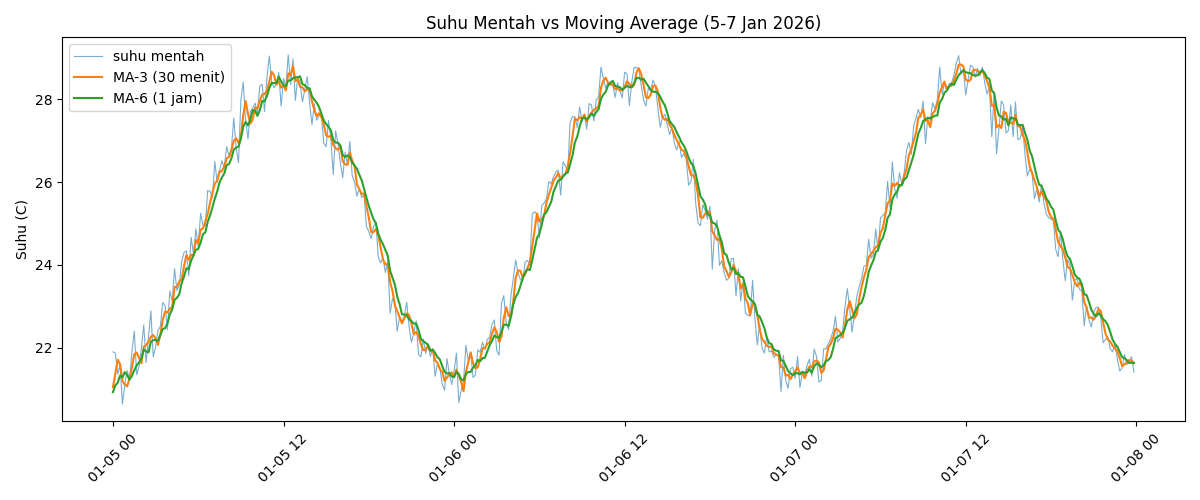

In [3]:
r = subprocess.run([sys.executable, "scripts/plot_room_features.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/features_moving_average.png")

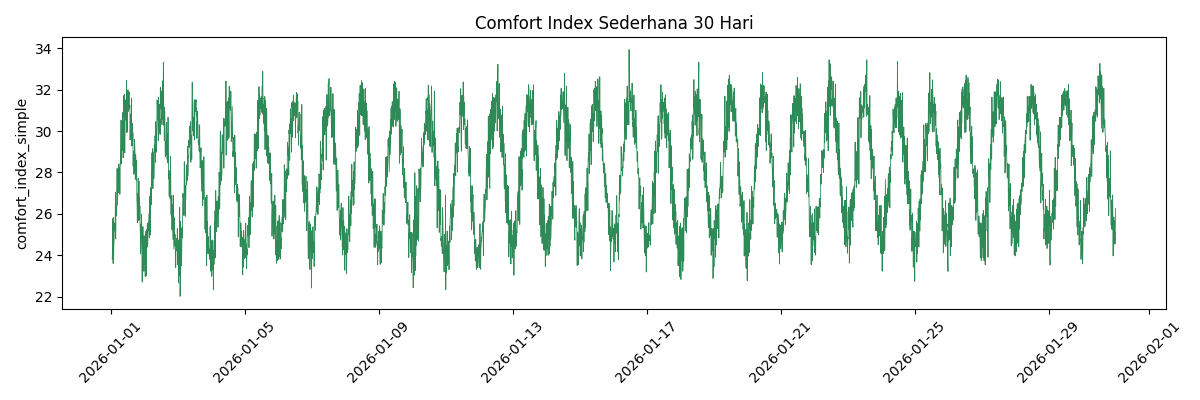

In [4]:
Image("outputs/figures/features_comfort_index.png")

## Penutup

25 kolom fitur siap dipakai model ML. Moving average menghaluskan noise harian, diff
menunjukkan laju perubahan, dan comfort index menggabungkan suhu-kelembaban. Fitur ini
dipakai pada Hands-on 23 (regresi) dan forecasting Bab 10.